In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yeonjiji/separation-data/test.jsonl
/kaggle/input/datasets/yeonjiji/separation-data/validate.jsonl
/kaggle/input/datasets/yeonjiji/separation-data/train.jsonl
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__results__.html
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__huggingface_repos__.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__notebook__.ipynb
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__output__.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/custom.css
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/README.md
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/checkpoint-603/adapter_model.safetensors
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/checkpoint-603/trainer_state.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm

In [2]:
%env CUDA_VISIBLE_DEVICES=0

%pip uninstall -y torchao

%pip install -q \
    transformers==5.16.1 \
    peft==0.20.0 \
    datasets \
    accelerate \
    scikit-learn

env: CUDA_VISIBLE_DEVICES=0
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 88.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 58.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import random
import torch
import numpy as np
import pandas as pd

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

MODEL_NAME = "Qwen/Qwen3-1.7B"

DEVICE = "cuda"

SEED = 2024
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [4]:
ADAPTER_PATH = "/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora-final"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Qwen3-1.7B
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="cuda"
)

# Fine-tuned model
ft_model = PeftModel.from_pretrained(
    base_model,
    ADAPTER_PATH
)

# evaluation mode
ft_model.eval()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Qwen3ForCausalLM(
      (model): Qwen3Model(
        (embed_tokens): Embedding(151936, 2048)
        (layers): ModuleList(
          (0-27): 28 x Qwen3DecoderLayer(
            (self_attn): Qwen3Attention(
              (q_proj): lora.Linear(
                (base_layer): Linear(in_features=2048, out_features=2048, bias=False)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=2048, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=2048, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): lora.Linear

In [5]:
from datasets import load_dataset

test_dataset = load_dataset(
    "json",
    data_files="/kaggle/input/datasets/yeonjiji/separation-data/test.jsonl",
    split="train"
)

len(test_dataset)

Generating train split: 0 examples [00:00, ? examples/s]

501

In [6]:
example = test_dataset[0]
messages = example["messages"]
messages

[{'role': 'system',
  'content': 'You are an expert liquid-liquid extraction chemist.\nUse the provided experiment description to predict the extraction selectivity.\nReturn only VL, L, U, M, H.'},
 {'role': 'user',
  'content': '2 M of CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C in n-dodecane is used to extract 10 mM Pu(IV) from an aqueous solution of 3 M HNO3 and 3 M nitrate at 20 C. The contact time is 20 min and the radiolytic dosage is 0 kGy.'},
 {'role': 'assistant', 'content': 'L'}]

In [7]:
prompt_messages = messages[:-1]
true_label = messages[-1]["content"].strip()

print(prompt_messages)
print(true_label)

[{'role': 'system', 'content': 'You are an expert liquid-liquid extraction chemist.\nUse the provided experiment description to predict the extraction selectivity.\nReturn only VL, L, U, M, H.'}, {'role': 'user', 'content': '2 M of CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C in n-dodecane is used to extract 10 mM Pu(IV) from an aqueous solution of 3 M HNO3 and 3 M nitrate at 20 C. The contact time is 20 min and the radiolytic dosage is 0 kGy.'}]
L


In [8]:
# the entire promopt is condensed into a single string
prompt = tokenizer.apply_chat_template(
    prompt_messages,
    tokenize=False,
    add_generation_prompt=True,    # Whether to end the prompt with the token that indicate the start of an assistant message
    enable_thinking=False,    # default for Qwen3 = True
)

# Tokenize the prompt
inputs = tokenizer(
    prompt,
    return_tensors="pt"
).to(DEVICE)

In [9]:
with torch.no_grad():
    output = ft_model.generate(
        **inputs,
        max_new_tokens=3,    # The maximum numbers of tokens to generate
        do_sample=False    # not use sampling -> Greedy Seearch
    )

generated = tokenizer.decode(
    output[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True    # skip special tokens (eos, pad, cls, etc.)
)

In [10]:
print("True :", true_label)
print("Predicted: ", generated)

True : L
Predicted:  U


In [11]:
from tqdm.auto import tqdm

LABELS = ["VL", "L", "U", "M", "H"]

# To check all test_dataset
y_true = []
y_pred = []

for example in tqdm(test_dataset):
    messages = example["messages"]
    prompt_messages = messages[:-1]
    true_label = messages[-1]["content"].strip()

    prompt = tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(DEVICE)

    with torch.no_grad():
        output = ft_model.generate(
            **inputs,
            max_new_tokens=3,
            do_sample=False,
        )

    generated = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

    pred_label=None

    # Sort by length descending to avoid partial prefix matching (defensive coding)
    # (e.g. matching "V" before "VL)
    for label in sorted(LABELS, key=len, reverse=True):
        if generated.startswith(label):
            pred_label=label
            break

    y_true.append(true_label)
    y_pred.append(pred_label)
        

  0%|          | 0/501 [00:00<?, ?it/s]

In [12]:
# Check the ft_model results

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_true, y_pred)

print("Accuracy: ", accuracy)
print("\nConfusion Matrix:")
print(
    confusion_matrix(y_true, y_pred, labels=LABELS)
)

print("\nClassification Report:")
print(
    classification_report(y_true, y_pred, labels=LABELS, zero_division=0)
)

Accuracy:  0.5868263473053892

Confusion Matrix:
[[ 24  21   6   1   0]
 [ 11  62  48   4   0]
 [  2  25 123  22   1]
 [  0   4  31  65   9]
 [  0   0   5  17  20]]

Classification Report:
              precision    recall  f1-score   support

          VL       0.65      0.46      0.54        52
           L       0.55      0.50      0.52       125
           U       0.58      0.71      0.64       173
           M       0.60      0.60      0.60       109
           H       0.67      0.48      0.56        42

    accuracy                           0.59       501
   macro avg       0.61      0.55      0.57       501
weighted avg       0.59      0.59      0.58       501



In [13]:
# to check any invalid predictions
invalid = [
    (i, true, pred)
    for i, (true, pred) in enumerate(zip(y_true, y_pred))
    if pred not in LABELS
]

print("Invalid predictions:", len(invalid))

invalid[:10]

Invalid predictions: 0


[]

In [14]:
validation_dataset = load_dataset(
    "json",
    data_files="/kaggle/input/datasets/yeonjiji/separation-data/validate.jsonl",
    split="train"
)

print(len(validation_dataset), len(test_dataset))

Generating train split: 0 examples [00:00, ? examples/s]

400 501


In [15]:
from contextlib import nullcontext

# Extract last token vectors for every layers
def extract_activations(model, dataset, disable_lora=False):

    all_activations = []
    labels = []

    model.eval()

    context = model.disable_adapter if disable_lora else None    # to run inference on the base model (ft -> not use)

    for example in tqdm(dataset):

        messages = example["messages"]
        prompt_messages = messages[:-1]
        label = messages[-1]["content"].strip()

        prompt = tokenizer.apply_chat_template(
            prompt_messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )

        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            add_special_tokens=False
        ).to(DEVICE)

        ctx = context() if context is not None else nullcontext()

        with ctx:
            with torch.no_grad():
                outputs = model(
                    **inputs,
                    output_hidden_states=True,    # return the hidden states
                    use_cache=False,
                    return_dict=True,    # return as ModelOutput instead of a plain tuple
                )

        activation = torch.stack([
            h[0, -1, :].float().cpu()    # [batch first sentence, last token, vector (2048)]
            for h in outputs.hidden_states
        ])

        all_activations.append(activation.numpy())
        labels.append(label)

    return np.stack(all_activations), np.array(labels)

In [16]:
ft_val_X, val_y = extract_activations(
    ft_model,
    validation_dataset,
    disable_lora=False
)

ft_test_X, test_y = extract_activations(
    ft_model,
    test_dataset,
    disable_lora=False
)

print(ft_val_X.shape)
print(ft_test_X.shape)

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/501 [00:00<?, ?it/s]

(400, 29, 2048)
(501, 29, 2048)


In [17]:
base_val_X, _ = extract_activations(
    ft_model,
    validation_dataset,
    disable_lora=True
)

base_test_X, _ = extract_activations(
    ft_model,
    test_dataset,
    disable_lora=True
)

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/501 [00:00<?, ?it/s]

In [18]:
# Save the activations

SAVE_PATH = "/kaggle/working/layer_activations.npz"
np.savez_compressed(
    SAVE_PATH,

    ft_val_X=ft_val_X,
    ft_test_X=ft_test_X,

    base_val_X=base_val_X,
    base_test_X=base_test_X,

    val_y=val_y,
    test_y=test_y
)

import os
print(os.path.exists(SAVE_PATH))
print(os.path.getsize(SAVE_PATH) / 1024**2, "MB")

True
240.84461212158203 MB


In [19]:
# to use train dataset to train SAE, save activations for train dataset

train_dataset = load_dataset(
    "json",
    data_files="/kaggle/input/datasets/yeonjiji/separation-data/train.jsonl",
    split="train"
)

ft_train_X, train_y = extract_activations(ft_model, train_dataset)
print(ft_train_X.shape)

Generating train split: 0 examples [00:00, ? examples/s]

  0%|          | 0/1602 [00:00<?, ?it/s]

(1602, 29, 2048)


In [20]:
# out of (1602, 29, 2048), juse used layer 15-23 

SAE_LAYERS = slice(15, 24)

np.savez_compressed(
    "/kaggle/working/acts_for_sae.npz",
    train=ft_train_X[:, SAE_LAYERS].astype(np.float16),
    val=ft_val_X[:, SAE_LAYERS].astype(np.float16),
    test=ft_test_X[:, SAE_LAYERS].astype(np.float16),
    train_y=train_y, val_y=val_y, test_y=test_y,
    layers=np.arange(15, 24),
)
del ft_train_X

**Note on Layer Indexing**\
Since saved activations cover layers 15–23, the array index is offset by 15:$$\text{Index} = \text{Layer} - 15 \quad (\text{e.g., Layer 19} \rightarrow 19 - 15 = 4)$$

## Probe

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

### - D-class accuracy

In [22]:
def layer_probe(train_X, train_y, test_X, test_y):

    accuracies = []
    n_layers = train_X.shape[1]

    for layer in tqdm(range(n_layers)):

        probe = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                C=0.1
            )
        )

        probe.fit(
            train_X[:, layer, :],
            train_y
        )

        pred = probe.predict(
            test_X[:, layer, :]
        )

        acc = accuracy_score(test_y, pred)

        accuracies.append(acc)

    return np.array(accuracies)

In [23]:
base_probe_acc = layer_probe(
    base_val_X, val_y, base_test_X, test_y
)

ft_probe_acc = layer_probe(
    ft_val_X, val_y, ft_test_X, test_y
)

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

In [24]:
probe_results = pd.DataFrame({
    "Layer": range(len(base_probe_acc)),
    "Base": base_probe_acc,
    "Fine-Tuned": ft_probe_acc
})

probe_results

,Layer,Base,Fine-Tuned
0,0,0.345309,0.345309
1,1,0.467066,0.463074
2,2,0.491018,0.489022
3,3,0.493014,0.495010
4,4,0.508982,0.508982
5,5,0.516966,0.510978
6,6,0.508982,0.499002
7,7,0.495010,0.497006
8,8,0.485030,0.493014
9,9,0.489022,0.508982


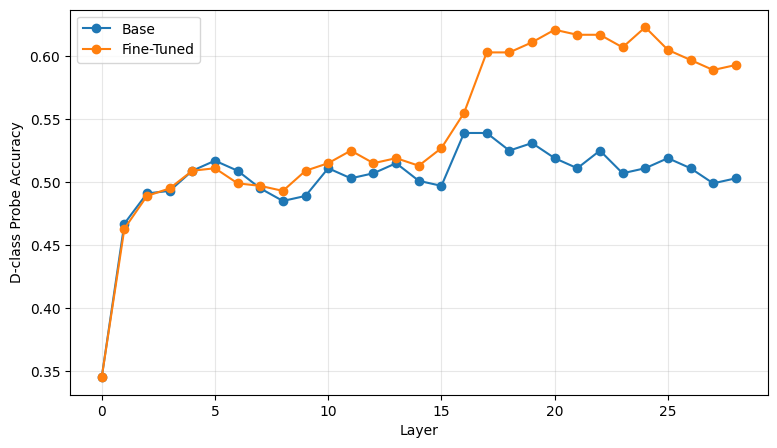

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    probe_results["Layer"],
    probe_results["Base"],
    marker="o",
    label="Base"
)

plt.plot(
    probe_results["Layer"],
    probe_results["Fine-Tuned"],
    marker="o",
    label="Fine-Tuned"
)

plt.xlabel("Layer")
plt.ylabel("D-class Probe Accuracy")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [26]:
# val + test = 901 -> 5-fold

from sklearn.model_selection import StratifiedKFold, cross_val_score

X_ft = np.concatenate([ft_val_X, ft_test_X])
X_base = np.concatenate([base_val_X, base_test_X])
y_all = np.concatenate([val_y, test_y])

def layer_probe_cv(X, y, layer_list):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    res = []
    for layer in tqdm(layer_list):
        probe = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, C=0.1)
        )
        scores = cross_val_score(probe, X[:, layer, :], y, cv=cv, n_jobs=-1)
        res.append((scores.mean(), scores.std()))

    return np.array(res)

PROBE_LAYERS = [0, 12, 19, 24]

ft_cv = layer_probe_cv(X_ft, y_all, PROBE_LAYERS)
base_cv = layer_probe_cv(X_base, y_all, PROBE_LAYERS)

y_shuf  = np.random.default_rng(SEED).permutation(y_all)
shuf_cv = layer_probe_cv(X_ft, y_shuf, PROBE_LAYERS)

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

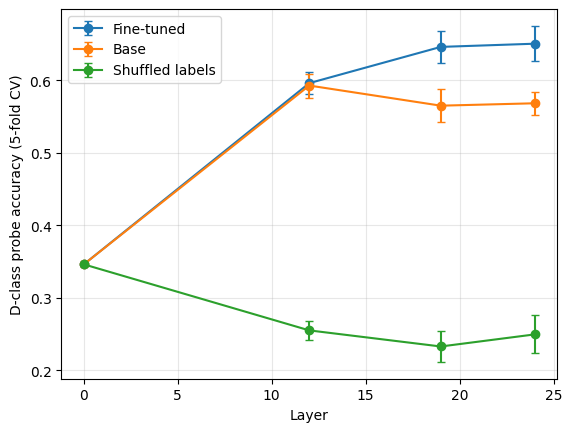

In [27]:
for res, name in [(ft_cv, "Fine-tuned"), (base_cv, "Base"), (shuf_cv, "Shuffled labels")]:
    plt.errorbar(PROBE_LAYERS, res[:, 0], yerr=res[:, 1], marker="o", capsize=3, label=name)

plt.xlabel("Layer"); plt.ylabel("D-class probe accuracy (5-fold CV)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### - Metal Identity

In [28]:
import re
from collections import Counter

def extract_metal(example):
    user_text = example["messages"][1]["content"]

    # find matched metal -> example: Th(IV), U(VI)
    match = re.search(
        r'\b(Am|Pa|U|Th|Pu|Np)\s*\([IVX]+\)',
        user_text
    )

    if match:
        return match.group(1)

    return None

val_metal_y = np.array([
    extract_metal(x) for x in validation_dataset
])

test_metal_y = np.array([
    extract_metal(x) for x in test_dataset
])

print("Validation: ", Counter(val_metal_y))
print("Test:", Counter(test_metal_y))

Validation:  Counter({np.str_('U'): 191, np.str_('Pu'): 115, np.str_('Np'): 37, np.str_('Th'): 34, np.str_('Am'): 19, np.str_('Pa'): 4})
Test: Counter({np.str_('U'): 220, np.str_('Pu'): 163, np.str_('Np'): 60, np.str_('Th'): 38, np.str_('Am'): 14, np.str_('Pa'): 6})


In [29]:
base_metal_acc = layer_probe(
    base_val_X, val_metal_y,
    base_test_X, test_metal_y
)

ft_metal_acc = layer_probe(
    ft_val_X, val_metal_y,
    ft_test_X, test_metal_y
)

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

In [30]:
metal_results = pd.DataFrame({
    "Layer": range(len(base_metal_acc)),
    "Base": base_metal_acc,
    "Fine-Tuned": ft_metal_acc
})

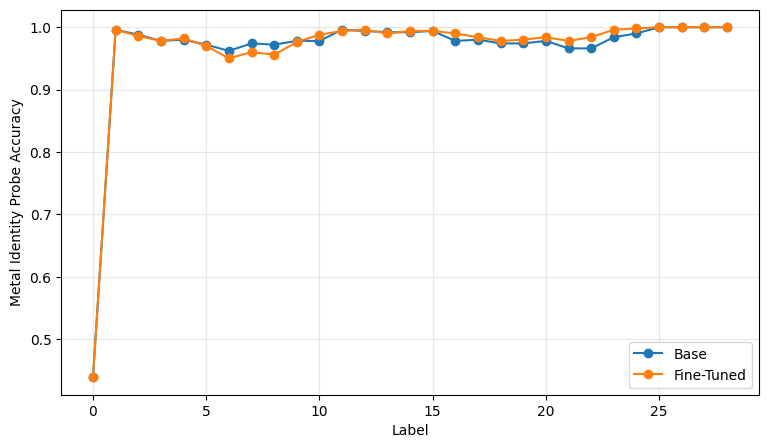

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(
    metal_results["Layer"],
    metal_results["Base"],
    marker="o",
    label="Base"
)

plt.plot(
    metal_results["Layer"],
    metal_results["Fine-Tuned"],
    marker="o",
    label="Fine-Tuned"
)

plt.xlabel("Label")
plt.ylabel("Metal Identity Probe Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [32]:
from sklearn.metrics import f1_score

def layer_probe_macro_f1(train_X, train_y, test_X, test_y):
    scores = []

    for layer in tqdm(range(train_X.shape[1])):
        probe = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                C=0.1
            )
        )

        probe.fit(train_X[:, layer, :], train_y)
        pred = probe.predict(test_X[:, layer, :])

        scores.append(f1_score(test_y, pred, average="macro"))

    return np.array(scores)

In [ ]:
base_metal_f1 = layer_probe_macro_f1(
    base_val_X, val_metal_y,
    base_test_X, test_metal_y
)

ft_metal_f1 = layer_probe_macro_f1(
    ft_val_X, val_metal_y,
    ft_test_X, test_metal_y
)

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

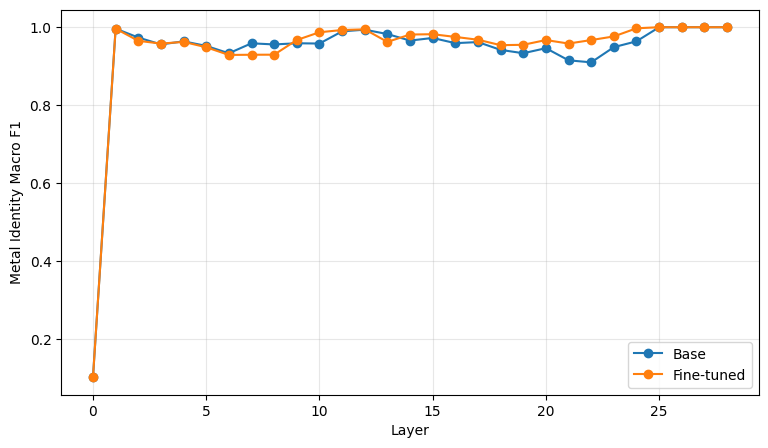

In [34]:
plt.figure(figsize=(9, 5))

plt.plot(base_metal_f1, marker="o", label="Base")
plt.plot(ft_metal_f1, marker="o", label="Fine-tuned")

plt.xlabel("Layer")
plt.ylabel("Metal Identity Macro F1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### - HNO3 Concentration

In [35]:
def extract_hno3(example):
    user_text = example["messages"][1]["content"]

    match = re.search(
        r'([\d.]+)\s*M\s*HNO3',
        user_text
    )

    if match:
        return float(match.group(1))
    return None

In [36]:
val_hno3 = np.array([
    extract_hno3(x) for x in validation_dataset
])

test_hno3 = np.array([
    extract_hno3(x) for x in test_dataset
])

print("Validation:", Counter(val_hno3))
print("Test:", Counter(test_hno3))

Validation: Counter({3.0: 85, 4.0: 59, 2.0: 49, 6.0: 46, 1.0: 39, 5.0: 21, None: 20, 0.5: 20, 8.0: 9, 10.0: 8, 0.01: 8, 0.1: 7, 0.2: 6, 0.005: 4, 7.0: 4, 9.0: 3, 0.09: 2, 0.6: 2, 0.08: 2, 0.3: 2, 0.8: 1, 0.07: 1, 0.9: 1, 0.7: 1})
Test: Counter({3.0: 113, 4.0: 75, 2.0: 67, 6.0: 45, None: 43, 1.0: 38, 5.0: 33, 0.5: 20, 0.1: 14, 0.01: 11, 0.2: 9, 7.0: 8, 8.0: 8, 10.0: 6, 0.09: 3, 0.005: 3, 0.3: 2, 0.4: 2, 0.08: 1})


In [37]:
# Check value "None"
for split_name, dataset, values in [
    ("validation", validation_dataset, val_hno3),
    ("test", test_dataset, test_hno3),
]:
    print(f"\n--- {split_name} ---")

    count = 0
    for i, value in enumerate(values):
        if value is None:
            print("\nINDEX: ", i)
            print(dataset[i]["messages"][1]["content"])
            count += 1

            if count >= 5:
                break


--- validation ---

INDEX:  8
0.4 M of CCCCCCCCCCCC(=O)N(CC)CC in toluene is used to extract trace U(VI) from an aqueous solution of unknown concentration HNO3 and unknown concentration nitrate at 20 C. The contact time is 30 min and the radiolytic dosage is 0 kGy.

INDEX:  9
2 M of CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)(C)C in n-dodecane is used to extract 0.7 mM Np(V) from an aqueous solution of 1 M  and 1 M nitrate at 20 C. The contact time is 5 min and the radiolytic dosage is 0 kGy.

INDEX:  22
1 M of CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C in n-dodecane is used to extract 0.1 mM U(VI) from an aqueous solution of unknown concentration HNO3, HF and 4 M nitrate at 20 C. The contact time is 30 min and the radiolytic dosage is 0 kGy.

INDEX:  71
0.2 M of CCCCCCCCCCCC(=O)N(CC)CC in toluene is used to extract trace U(VI) from an aqueous solution of unknown concentration HNO3 and unknown concentration nitrate at 20 C. The contact time is 30 min and the radiolytic dosage is 0 kGy.

INDEX:  79
1 M of

In [38]:
# Use only clean data
val_mask= np.array([x is not None for x in val_hno3])
test_mask = np.array([x is not None for x in test_hno3])

val_hno3_clean = val_hno3[val_mask].astype(float)
test_hno3_clean = test_hno3[test_mask].astype(float)

print("Validation usable:", len(val_hno3_clean))
print("Test usable:", len(test_hno3_clean))

Validation usable: 380
Test usable: 458


In [39]:
base_val_hno3_X = base_val_X[val_mask]
base_test_hno3_X = base_test_X[test_mask]

ft_val_hno3_X = ft_val_X[val_mask]
ft_test_hno3_X = ft_test_X[test_mask]

# Apply log10 scaling across orders of magnitude spanning from 10^-3 to 10^1 M.
val_hno3_log = np.log10(val_hno3_clean)
test_hno3_log = np.log10(test_hno3_clean)

In [40]:
# Layer-wise regression probe

from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

In [41]:
def layer_regression_probe(train_X, train_y, test_X, test_y):
    r2_scores = []

    for layer in tqdm(range(train_X.shape[1])):
        probe = make_pipeline(
            StandardScaler(),
            Ridge(alpha=10.0)
        )

        probe.fit(
            train_X[:, layer, :],
            train_y
        )

        pred = probe.predict(
            test_X[:, layer, :]
        )

        r2_scores.append(
            r2_score(test_y, pred)
        )

    return np.array(r2_scores)

In [42]:
base_hno3_r2 = layer_regression_probe(
    base_val_hno3_X, val_hno3_log, base_test_hno3_X, test_hno3_log
)

ft_hno3_r2 = layer_regression_probe(
    ft_val_hno3_X, val_hno3_log, ft_test_hno3_X, test_hno3_log
)

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

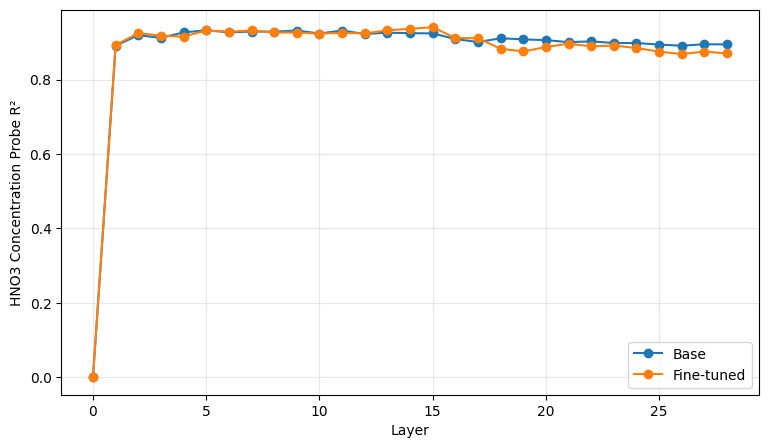

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    base_hno3_r2,
    marker="o",
    label="Base"
)

plt.plot(
    ft_hno3_r2,
    marker="o",
    label="Fine-tuned"
)

plt.xlabel("Layer")
plt.ylabel("HNO3 Concentration Probe R²")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### - Ligand / SMILES information probe

In [44]:
def extract_ligand(example):
    user_text = example["messages"][1]["content"]

    match = re.search(
        r'[\d.]+\s*M\s+of\s+(.+?)\s+in\s+',
        user_text
    )

    if match:
        return match.group(1).strip()

    return None


val_ligand = np.array([
    extract_ligand(x) for x in validation_dataset
])

test_ligand = np.array([
    extract_ligand(x) for x in test_dataset
])

print("Validation unique ligands:", len(set(val_ligand)))
print("Test unique ligands:", len(set(test_ligand)))

print("\nValidation:")
print(Counter(val_ligand).most_common(20))

print("\nTest:")
print(Counter(test_ligand).most_common(20))

Validation unique ligands: 45
Test unique ligands: 45

Validation:
[('CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C', 86), ('CCCCC(CC)CN(CC(CC)CCCC)C(=O)CCC', 68), ('CCCCCCCC(=O)N(CCCCCC)CCCCCC', 65), (None, 26), ('CCCCCCN(CCCCCC)C(=O)CCCCC', 22), ('CCCCCCCCCC(=O)N(CCCCCC)CCCCCC', 13), ('CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)(C)C', 11), ('CCCCC(CC)C(=O)N(CCCC)CCCC', 10), ('CCCCCC(=O)N(CC(CC)CCCC)CC(CC)CCCC', 8), ('CCCCCCN(CCCCCC)C(=O)C(CC)CCCC', 7), ('CCCCCCCCN(CCCCCCCC)C(=O)CCCCCCC', 6), ('CCC(C)CN(CC(C)C)C(=O)C(C)C', 5), ('CCCCCCCCCCCC(=O)N(CC)CC', 5), ('CCCCC(CC)CN(CC(CC)CCCC)C(=O)CC', 5), ('CCCCN(CCCC)C(=O)CCC', 5), ('CCCCC(CC)CN(CC(CC)CCCC)C(C)=O', 5), ('CCCCCCCCN(CCCCCCCC)C(=O)C(CC)CCCC', 4), ('CCCCC(CC)CN(CC(CC)CCCC)C(=O)CC(C)(C)C', 4), ('CCCCCC(=O)N(C(C)CC)C(C)CC', 3), ('CCCCCCCCN(CCCCCCCC)C(=O)CCC', 3)]

Test:
[('CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C', 114), ('CCCCC(CC)CN(CC(CC)CCCC)C(=O)CCC', 85), ('CCCCCCCC(=O)N(CCCCCC)CCCCCC', 82), (None, 24), ('CCCCCCN(CCCCCC)C(=O)CCCCC', 24), ('CCCCCCCCCCCC(=O

In [45]:
# Check value "None"
for split_name, dataset, ligands in [
    ("validation", validation_dataset, val_ligand),
    ("test", test_dataset, test_ligand),
]:
    print(f"\n--- {split_name} ---")

    count = 0
    for i, ligand in enumerate(ligands):
        if ligand is None:
            print("\nINDEX: ", i)
            print(dataset[i]["messages"][1]["content"])
            count += 1

            if count >= 5:
                break


--- validation ---

INDEX:  23
unknown concentration of CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C in n-dodecane is used to extract trace U(VI) from an aqueous solution of 4 M HNO3 and 4 M nitrate at about 20 C. The contact time is 60 min and the radiolytic dosage is 0 kGy.

INDEX:  31
unknown concentration of CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C in n-dodecane is used to extract 2000 mM U(VI) from an aqueous solution of 3 M HNO3 and 3 M nitrate at 20 C. The contact time is 60 min and the radiolytic dosage is 0 kGy.

INDEX:  57
unknown concentration of CCCCCCCCCCCC(=O)N(CCCCCCCC)CCCCCCCC in toluene is used to extract trace U(VI) from an aqueous solution of 2 M HNO3 and 2 M nitrate at 20 C. The contact time is 30 min and the radiolytic dosage is 0 kGy.

INDEX:  80
unknown concentration of CCCCC(CC)CN(CC(CC)CCCC)C(=O)CCC in n-dodecane is used to extract trace Pu(IV) from an aqueous solution of 3 M HNO3 and 3 M nitrate at about 20 C. The contact time is 60 min and the radiolytic dosage is 0 kGy.

IND

In [46]:
# Fix: include "unknown concentraion"
def extract_ligand(example):
    user_text = example["messages"][1]["content"]

    # "0.5 M of <SMILES> in ..." Or
    # "unknown concentration of <SMILES> in ..."
    match = re.search(
        r'(?:[\d.]+\s*M|unknown concentration)\s+of\s+(.+?)\s+in\s+',
        user_text
    )

    if match:
        return match.group(1).strip()

    return None

In [47]:
val_ligand = np.array([
    extract_ligand(x) for x in validation_dataset
])

test_ligand = np.array([
    extract_ligand(x) for x in test_dataset
])

print("Validation:", Counter(val_ligand).most_common(10))
print("Test:", Counter(test_ligand).most_common(10))

print("Validation None:", sum(x is None for x in val_ligand))
print("Test None:", sum(x is None for x in test_ligand))

Validation: [(np.str_('CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C'), 89), (np.str_('CCCCC(CC)CN(CC(CC)CCCC)C(=O)CCC'), 77), (np.str_('CCCCCCCC(=O)N(CCCCCC)CCCCCC'), 65), (np.str_('CCCCCCN(CCCCCC)C(=O)CCCCC'), 22), (np.str_('CCCCCCCCCC(=O)N(CCCCCC)CCCCCC'), 13), (np.str_('CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)(C)C'), 11), (np.str_('CCCCC(CC)C(=O)N(CCCC)CCCC'), 10), (np.str_('CCCCCC(=O)N(CC(CC)CCCC)CC(CC)CCCC'), 8), (np.str_('CCCCCCN(CCCCCC)C(=O)C(CC)CCCC'), 7), (np.str_('CCCCCCCCN(CCCCCCCC)C(=O)CCC'), 7)]
Test: [(np.str_('CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C'), 119), (np.str_('CCCCC(CC)CN(CC(CC)CCCC)C(=O)CCC'), 90), (np.str_('CCCCCCCC(=O)N(CCCCCC)CCCCCC'), 82), (np.str_('CCCCCCN(CCCCCC)C(=O)CCCCC'), 24), (np.str_('CCCCCCCCCCCC(=O)N(CC)CC'), 22), (np.str_('CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)(C)C'), 13), (np.str_('CCCCCCCCCC(=O)N(CCCCCC)CCCCCC'), 13), (np.str_('CCCCN(CCCC)C(=O)CCC'), 11), (np.str_('CCCCC(CC)C(=O)N(CCCC)CCCC'), 9), (np.str_('CCCCC(CC)CN(CC(CC)CCCC)C(=O)CC'), 8)]
Validation None: 0
Test None: 0

In [48]:
%pip install -q rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 47.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [49]:
# Ligand structural information

from rdkit import Chem
from rdkit.Chem import Descriptors

def ligand_properties(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    atoms = [atom.GetSymbol() for atom in mol.GetAtoms()]

    return {
        "carbon_count": atoms.count("C"),
        "nitrogen_count": atoms.count("N"),
        "oxygen_count": atoms.count("O"),
        "heavy_atom_count": mol.GetNumHeavyAtoms(),
        "molecular_weight": Descriptors.MolWt(mol),
    }

In [50]:
val_props = [ligand_properties(s) for s in val_ligand]
test_props = [ligand_properties(s) for s in test_ligand]

print("Invalid validation:", sum(x is None for x in val_props))
print("Invalid test:", sum(x is None for x in test_props))

Invalid validation: 0
Invalid test: 0


In [51]:
for prop in [
    "carbon_count",
    "nitrogen_count",
    "oxygen_count",
    "heavy_atom_count",
]:

    print(f"\n--- {prop} ---")

    print(
        "Validation:",
        Counter(x[prop] for x in val_props)
    )


--- carbon_count ---
Validation: Counter({20: 252, 18: 29, 22: 25, 16: 22, 21: 14, 13: 10, 24: 10, 12: 10, 14: 6, 19: 6, 17: 6, 28: 5, 15: 3, 10: 2})

--- nitrogen_count ---
Validation: Counter({1: 400})

--- oxygen_count ---
Validation: Counter({1: 400})

--- heavy_atom_count ---
Validation: Counter({22: 252, 20: 29, 24: 25, 18: 22, 23: 14, 15: 10, 26: 10, 14: 10, 16: 6, 21: 6, 19: 6, 30: 5, 17: 3, 12: 2})


In [52]:
val_mw = np.array([x["molecular_weight"] for x in val_props])

print("MW min:", val_mw.min())
print("MW max:", val_mw.max())
print("MW unique:", len(np.unique(np.round(val_mw, 2))))

MW min: 171.28399999999996
MW max: 423.7700000000004
MW unique: 18


In [53]:
# Molecular Weight probe

val_mw = np.array([
    x["molecular_weight"] for x in val_props
])

test_mw = np.array([
    x["molecular_weight"] for x in test_props
])

print(val_mw.shape, test_mw.shape)
print(val_mw.min(), val_mw.max())

(400,) (501,)
171.28399999999996 423.7700000000004


In [54]:
base_mw_r2 = layer_regression_probe(
    base_val_X, val_mw, base_test_X, test_mw
)

ft_mw_r2 = layer_regression_probe(
    ft_val_X, val_mw, ft_test_X, test_mw
)

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

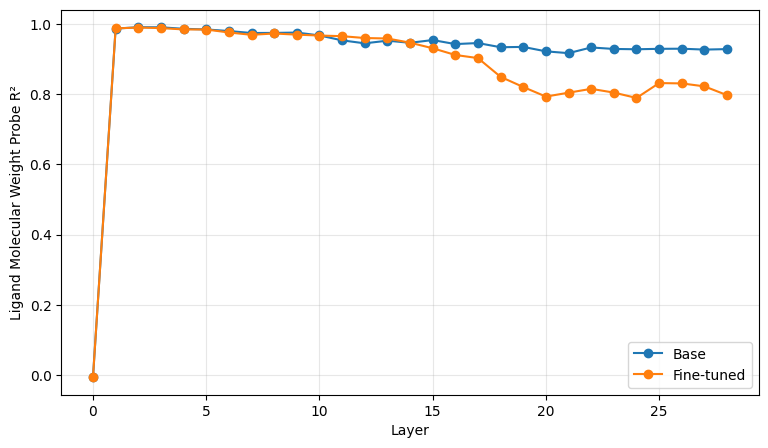

In [55]:
plt.figure(figsize=(9, 5))

plt.plot(
    base_mw_r2,
    marker="o",
    label="Base"
)

plt.plot(
    ft_mw_r2,
    marker="o",
    label="Fine-tuned"
)

plt.xlabel("Layer")
plt.ylabel("Ligand Molecular Weight Probe R²")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Counterfactual

In [56]:
# Generate a function for counterfactual: change the concentration of HNO3

def extract_conc(text, name):
    match = re.search(rf'([\d.]+)\s*M\s*{name}', text)
    return float(match.group(1)) if match else None

def make_hno3_counterfactual(example, new_hno3):
    messages = example["messages"]
    user_text = messages[1]["content"]

    # original concentrations
    old_hno3 = extract_conc(user_text, "HNO3")
    old_nitrate = extract_conc(user_text, "nitrate")

    # replace HNO3
    new_text = re.sub(
        r'([\d.]+)\s*M\s*HNO3',
        f'{new_hno3:g} M HNO3',
        user_text
    )

    # replace nitrate
    if old_nitrate is not None and old_hno3 is not None:
        extra_nitrate = max(old_nitrate - old_hno3, 0)
        new_nitrate = new_hno3 + extra_nitrate
        new_text = re.sub(
            r'([\d.]+)\s*M\s*nitrate',
            f'{new_nitrate:g} M nitrate',
            new_text
        )

    return [messages[0], {"role": "user", "content": new_text}]

In [57]:
# ex = test_dataset[1]
# print(ex["messages"][1]["content"])
# print(make_hno3_counterfactual(ex, 6)[1]["content"])

### Prediction + activation

In [58]:
LABELS

['VL', 'L', 'U', 'M', 'H']

In [59]:
def get_prediction_and_activations(model, messages):
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to(DEVICE)

    with torch.no_grad():
        outputs = model(
            **inputs,
            output_hidden_states=True,
            use_cache=False,
            return_dict=True
        )

    logits = outputs.logits[0, -1]

    # label token logits
    label_scores = {}

    for label in LABELS:
        token_id = tokenizer.encode(
            label,
            add_special_tokens=False
        )[0]

        label_scores[label] = logits[token_id].item()

    prediction = max(
        label_scores,
        key=label_scores.get
    )

    activations = np.stack([
        h[0, -1, :].float().cpu().numpy()
        for h in outputs.hidden_states
    ])

    return prediction, label_scores, activations

In [60]:
# Example

idx = 0

example = test_dataset[idx]

print(example["messages"][1]["content"])
print("True label:", example["messages"][-1]["content"])

2 M of CCCCC(CC)CN(CC(CC)CCCC)C(=O)C(C)C in n-dodecane is used to extract 10 mM Pu(IV) from an aqueous solution of 3 M HNO3 and 3 M nitrate at 20 C. The contact time is 20 min and the radiolytic dosage is 0 kGy.
True label: L


In [61]:
# 1M vs 6M

original_messages = example["messages"][:-1]

cf_1M = make_hno3_counterfactual(example, new_hno3=1)
cf_6M = make_hno3_counterfactual(example, new_hno3=6)

In [62]:
pred_1M, scores_1M, act_1M = get_prediction_and_activations(ft_model, cf_1M)
pred_6M, scores_6M, act_6M = get_prediction_and_activations(ft_model, cf_6M)

print("1 M prediction:", pred_1M)
print("6 M prediction:", pred_6M)

print("\n1 M scores:")
print(scores_1M)

print("\n6 M scores:")
print(scores_6M)

1 M prediction: U
6 M prediction: U

1 M scores:
{'VL': 30.484375, 'L': 32.59375, 'U': 32.65625, 'M': 30.453125, 'H': 28.453125}

6 M scores:
{'VL': 28.796875, 'L': 30.84375, 'U': 33.09375, 'M': 32.8125, 'H': 31.65625}


In [63]:
from sklearn.metrics.pairwise import cosine_similarity

layer_distance = []

for layer in range(act_1M.shape[0]):
    
    sim = cosine_similarity(
        act_1M[layer].reshape(1, -1),
        act_6M[layer].reshape(1, -1)
    )[0, 0]

    layer_distance.append(1 - sim)

layer_distance = np.array(layer_distance)

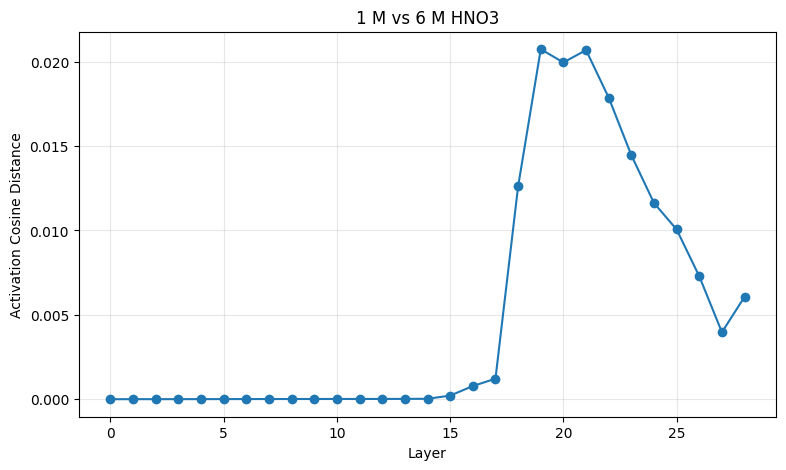

In [64]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(len(layer_distance)),
    layer_distance,
    marker="o"
)

plt.xlabel("Layer")
plt.ylabel("Activation Cosine Distance")
plt.title("1 M vs 6 M HNO3")
plt.grid(alpha=0.3)

plt.show()

In [65]:
# Expand to more examples

valid_idx = np.where(
    np.array([x is not None for x in test_hno3])
)[0]

rng = np.random.default_rng(SEED)

sample_idx = rng.choice(
    valid_idx,
    size=min(100, len(valid_idx)),
    replace=False
)

print("Examples:", len(sample_idx))

Examples: 100


In [66]:
import torch.nn.functional as F

CLASS_VALUE = {"VL":0, "L":1, "U":2, "M":3, "H":4}

all_distances = []
class_shifts = []
prediction_changes = []

for idx in tqdm(sample_idx):
    example = test_dataset[int(idx)]

    msg_1M = make_hno3_counterfactual(example, 1)
    msg_6M = make_hno3_counterfactual(example, 6)

    pred_1M, scores_1M, act_1M = get_prediction_and_activations(ft_model, msg_1M)
    pred_6M, scores_6M, act_6M = get_prediction_and_activations(ft_model, msg_6M)

    # Layer-wise activation distance
    distances = []

    for layer in range(act_1M.shape[0]):
        a = act_1M[layer]
        b = act_6M[layer]

        cosine_sim = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

        distances.append(1 - cosine_sim)

    all_distances.append(distances)

    # VL/L/U/M/H relative probability
    logits_1 = torch.tensor([scores_1M[x] for x in LABELS])
    logits_6 = torch.tensor([scores_6M[x] for x in LABELS])

    p1 = F.softmax(logits_1, dim=0).numpy()
    p6 = F.softmax(logits_6, dim=0).numpy()

    values = np.array([
        CLASS_VALUE[x] for x in LABELS
    ])

    expected_1 = np.sum(p1 * values)
    expected_6 = np.sum(p6 * values)

    class_shifts.append(expected_6 - expected_1)

    prediction_changes.append(
        pred_1M != pred_6M
    )

all_distances = np.array(all_distances)
class_shifts = np.array(class_shifts)

  0%|          | 0/100 [00:00<?, ?it/s]

In [67]:
print(
    "Prediction changed:",
    np.mean(prediction_changes)
)

print(
    "Mean D-class shift (6M - 1M):",
    class_shifts.mean()
)

print(
    "Median D-class shift:",
    np.median(class_shifts)
)

Prediction changed: 0.58
Mean D-class shift (6M - 1M): 0.7569741254889406
Median D-class shift: 0.6096518544945866


In [68]:
# layse-wise average counterfactual
mean_distance = all_distances.mean(axis=0)

sem_distance = (
    all_distances.std(axis=0)
    / np.sqrt(all_distances.shape[0])
)

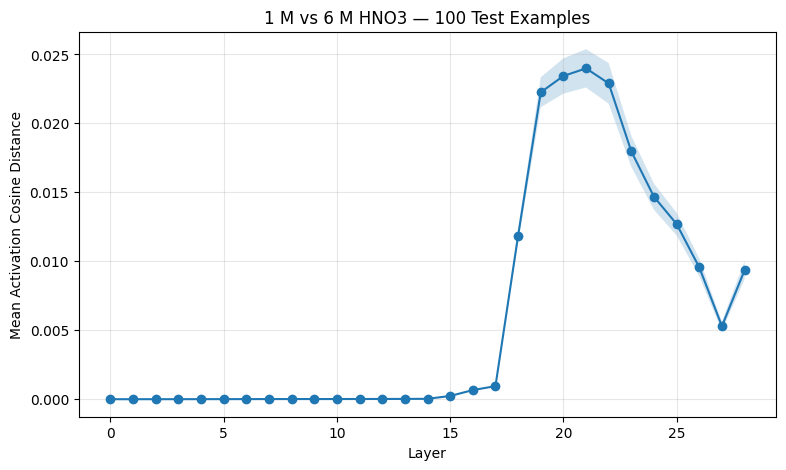

In [69]:
plt.figure(figsize=(9, 5))

layers = np.arange(len(mean_distance))

plt.plot(
    layers,
    mean_distance,
    marker="o"
)

plt.fill_between(
    layers,
    mean_distance - sem_distance,
    mean_distance + sem_distance,
    alpha=0.2
)

plt.xlabel("Layer")
plt.ylabel("Mean Activation Cosine Distance")
plt.title("1 M vs 6 M HNO3 — 100 Test Examples")
plt.grid(alpha=0.3)

plt.show()

In [70]:
# expected D-class across HNO3 concentrations

def expected_from_scores(scores):
    logits = torch.tensor([scores[x] for x in LABELS])
    p = torch.softmax(logits, dim=0).numpy()
    return np.sum(p * np.array([0, 1, 2, 3, 4]))

HNO3_GRID = [0.5, 1, 2, 3, 4, 6, 8]
dose = []

for idx in tqdm(sample_idx):
    ex = test_dataset[int(idx)]
    row = []
    for c in HNO3_GRID:
        _, scores, _ = get_prediction_and_activations(
            ft_model, make_hno3_counterfactual(ex, c)
        )
        row.append(expected_from_scores(scores))
    dose.append(row)

dose = np.array(dose)

  0%|          | 0/100 [00:00<?, ?it/s]

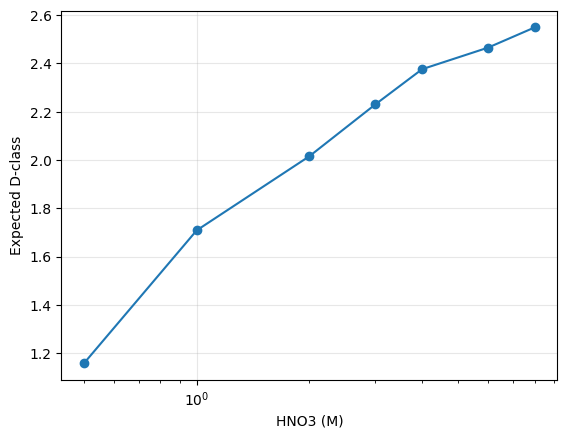

In [71]:
plt.plot(HNO3_GRID, dose.mean(axis=0), marker="o")
plt.xscale("log")
plt.xlabel("HNO3 (M)"); plt.ylabel("Expected D-class")
plt.grid(alpha=0.3); plt.show()

## Activation Patching

In [72]:
# Find Qwen transformer blocks 
layers = ft_model.base_model.model.model.layers

print("Number of transformer blocks:", len(layers))

Number of transformer blocks: 28


In [73]:
LABEL_VALUES = np.array([0, 1, 2, 3, 4])

label_token_ids = [
    tokenizer.encode(label, add_special_tokens=False)[0]
    for label in LABELS
]

def expected_d_from_logits(logits):
    label_logits = logits[label_token_ids]

    probs = torch.softmax(
        label_logits.float(),
        dim=-1
    ).cpu().numpy()

    return np.sum(probs * LABEL_VALUES)

In [74]:
def prepare(messages):
    prompt = tokenizer.apply_chat_template(
        messages, 
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )
    return tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(DEVICE)

def run_patching(model, msg_1M, msg_6M, patch_layers):
    patch_layers = list(patch_layers)
    inputs_1M, inputs_6M = prepare(msg_1M), prepare(msg_6M)

    # check if token length match
    if inputs_1M["input_ids"].shape != inputs_6M["input_ids"].shape:
        return np.full(len(patch_layers), np.nan)

    # Run the donor (6M) once and cache hidden states of all layers
    with torch.no_grad():
        donor_hidden = model(
            **inputs_6M,
            output_hidden_states=True,
            use_cache=False
        ).hidden_states

    # 
    scores = []
    for k in patch_layers:
        donor_act = donor_hidden[k][:, -1, :].clone()    # donor last-token vector at hidden state k

        # Bind donor_act as a default argument so each hook keeps its own layer's vector
        def patch_hook(module, inputs, output, donor_act=donor_act):
            if isinstance(output, tuple):
                hidden = output[0].clone()
                hidden[:, -1, :] = donor_act.to(hidden.dtype)
                return (hidden,) + output[1:]
            hidden = output.clone()
            hidden[:, -1, :] = donor_act.to(hidden.dtype)
            return hidden

        handle = layers[k - 1].register_forward_hook(patch_hook)    # hidden_states[k] is the output of block k, i.e. layers[k-1]
        try:
            with torch.no_grad():
                logits = model(**inputs_1M, use_cache=False).logits[0, -1]
        finally:
            handle.remove()

        scores.append(expected_d_from_logits(logits))

    return np.array(scores)

In [75]:
# One example
example = test_dataset[int(sample_idx[0])]

msg_1M = make_hno3_counterfactual(example, 1)
msg_6M = make_hno3_counterfactual(example, 6)

pred_1, scores_1, _ = get_prediction_and_activations(ft_model, msg_1M)
pred_6, scores_6, _ = get_prediction_and_activations(ft_model, msg_6M)

baseline_1 = expected_from_scores(scores_1)
baseline_6 = expected_from_scores(scores_6)


print("1 M:", pred_1, baseline_1)
print("6 M:", pred_6, baseline_6)

1 M: U 2.0465086745098233
6 M: U 2.530394913861528


In [76]:
print(msg_1M[1]["content"])
print(msg_6M[1]["content"])

1 M of CCCCCCCC(=O)N(CCCCCC)CCCCCC in n-dodecane is used to extract 1000 mM U(VI) from an aqueous solution of 1 M HNO3 and 1 M nitrate at 20 C. The contact time is 30 min and the radiolytic dosage is 0 kGy.
1 M of CCCCCCCC(=O)N(CCCCCC)CCCCCC in n-dodecane is used to extract 1000 mM U(VI) from an aqueous solution of 6 M HNO3 and 6 M nitrate at 20 C. The contact time is 30 min and the radiolytic dosage is 0 kGy.


In [77]:
PATCH_LAYERS = list(range(1, 29))

patched_scores = run_patching(ft_model, msg_1M, msg_6M, PATCH_LAYERS)

recovery_one = (patched_scores - baseline_1) / (baseline_6 - baseline_1)

for k, s, r in zip(PATCH_LAYERS, patched_scores, recovery_one):
    print(f"layer {k:2d} | expected D {s:.3f} | recovery {r:.2f}")

layer  1 | expected D 2.047 | recovery -0.00
layer  2 | expected D 2.047 | recovery -0.00
layer  3 | expected D 2.047 | recovery -0.00
layer  4 | expected D 2.046 | recovery -0.00
layer  5 | expected D 2.046 | recovery -0.00
layer  6 | expected D 2.047 | recovery -0.00
layer  7 | expected D 2.047 | recovery 0.00
layer  8 | expected D 2.047 | recovery -0.00
layer  9 | expected D 2.047 | recovery -0.00
layer 10 | expected D 2.047 | recovery -0.00
layer 11 | expected D 2.047 | recovery -0.00
layer 12 | expected D 2.049 | recovery 0.00
layer 13 | expected D 2.049 | recovery 0.00
layer 14 | expected D 2.051 | recovery 0.01
layer 15 | expected D 2.067 | recovery 0.04
layer 16 | expected D 2.097 | recovery 0.10
layer 17 | expected D 2.121 | recovery 0.15
layer 18 | expected D 2.409 | recovery 0.75
layer 19 | expected D 2.483 | recovery 0.90
layer 20 | expected D 2.487 | recovery 0.91
layer 21 | expected D 2.494 | recovery 0.92
layer 22 | expected D 2.511 | recovery 0.96
layer 23 | expected D 

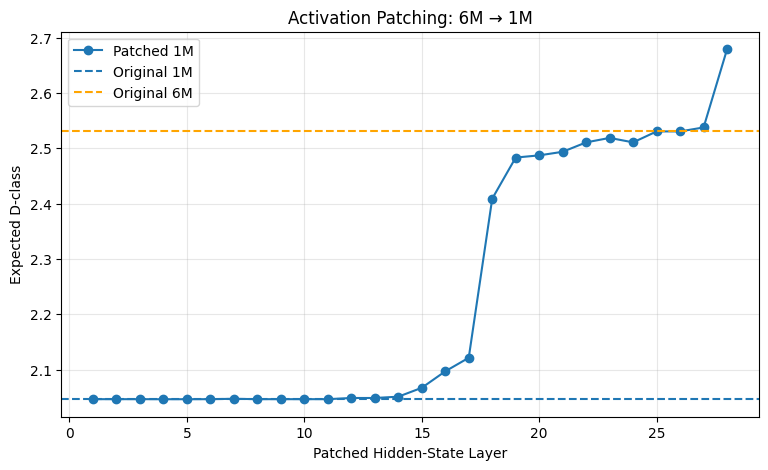

In [78]:
plt.figure(figsize=(9, 5))

plt.plot(PATCH_LAYERS, patched_scores, marker="o", label="Patched 1M")
plt.axhline(baseline_1, linestyle="--", label="Original 1M")
plt.axhline(baseline_6, linestyle="--", label="Original 6M", color="orange")

plt.xlabel("Patched Hidden-State Layer")
plt.ylabel("Expected D-class")
plt.title("Activation Patching: 6M → 1M")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [79]:
# Use 50 examples
# ft_model + base
PATCH_LAYERS = list(range(1, 28))    # exclude layer 29

patch_sample_idx = sample_idx[:50]

def get_baselines(model, m1, m6):
    _, s1, _ = get_prediction_and_activations(model, m1)
    _, s6, _ = get_prediction_and_activations(model, m6)
    return expected_from_scores(s1), expected_from_scores(s6)

ft_rows, base_rows = [], []

for idx in tqdm(patch_sample_idx):
    ex = test_dataset[int(idx)]
    m1 = make_hno3_counterfactual(ex, 1)
    m6 = make_hno3_counterfactual(ex, 6)

    # fine-tunes (LoRA on)
    b1, b6 = get_baselines(ft_model, m1, m6)
    ft_rows.append((b1, b6, run_patching(ft_model, m1, m6, PATCH_LAYERS)))

    # base (LoRA off)
    with ft_model.disable_adapter():
        b1, b6 = get_baselines(ft_model, m1, m6)
        base_rows.append((b1, b6, run_patching(ft_model, m1, m6, PATCH_LAYERS)))

def recovery(rows, min_shift=0.1):
    out = []
    for b1, b6, scores in rows:
        if abs(b6 - b1) >= min_shift:
            out.append((scores - b1) / (b6 - b1))
    return np.array(out)

ft_rec = recovery(ft_rows)
base_rec = recovery(base_rows)

print("used samples - ft:", len(ft_rec), "| base:", len(base_rec))
print("mean 1M→6M shift - ft:", np.mean([b6 - b1 for b1, b6, _ in ft_rows]), "| base:", np.mean([b6 - b1 for b1, b6, _ in base_rows]))

  0%|          | 0/50 [00:00<?, ?it/s]

used samples - ft: 50 | base: 0
mean 1M→6M shift - ft: 0.6765816649134863 | base: -0.002358005990536185


In [80]:
base_b1 = [b1 for b1, _, _ in base_rows]
print("base 1M expected D: mean", np.mean(base_b1), "std", np.std(base_b1))

base 1M expected D: mean 0.35042014169710456 std 0.4935719379075121


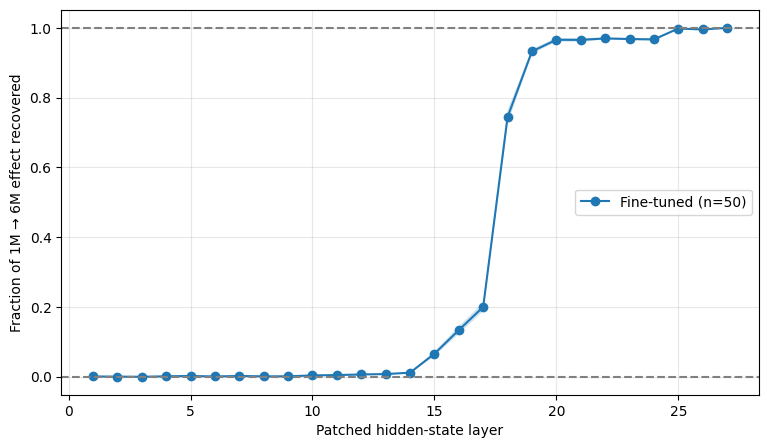

In [81]:
patch_layer_arr = np.array(PATCH_LAYERS)
plt.figure(figsize=(9, 5))

for rec, name in [(ft_rec, "Fine-tuned"), (base_rec, "Base")]:
    if len(rec) == 0:
        continue
    mean = np.nanmean(rec, axis=0)
    sem = np.nanstd(rec, axis=0) / np.sqrt(np.sum(~np.isnan(rec), axis=0))
    plt.plot(patch_layer_arr, mean, marker="o", label=f"{name} (n={len(rec)})")
    plt.fill_between(patch_layer_arr, mean - sem, mean + sem, alpha=0.2)

plt.axhline(0, linestyle="--", color="gray")
plt.axhline(1, linestyle="--", color="gray")
plt.xlabel("Patched hidden-state layer")
plt.ylabel("Fraction of 1M → 6M effect recovered")
plt.legend(); plt.grid(alpha=0.3); plt.show()

> * Before fine-tuning, the base model selected VL for most inputs and did not perform the classification task in a meaningful way.
> * Its outputs varied somewhat across inputs, but showed no response to changes in HNO₃ concentration (1 M → 6 M; mean Δ expected D-class ≈ 0.00).
> * In contrast, the fine-tuned model shifted its prediction toward higher D-classes by +0.68 on average.
> * Activation patching showed that this concentration information is routed to the final token position between layers 17 and 19: patching the  final-token activation from layer 19 onward recovered over 90% of the 1 M → 6 M effect, while patching at layers 1–14 had no effect.

In [82]:
np.savez(
    "/kaggle/working/counterfactual_patching_results.npz",
    sample_idx=sample_idx,
    hno3_grid=np.array(HNO3_GRID),
    dose=dose,
    patch_sample_idx=patch_sample_idx,
    patch_layers=patch_layer_arr,
    ft_baselines=np.array([(b1, b6) for b1, b6, _ in ft_rows]),
    ft_scores=np.array([s for _, _, s in ft_rows]),
    base_baselines=np.array([(b1, b6) for b1, b6, _ in base_rows]),
    base_scores=np.array([s for _, _, s in base_rows]),
)